
Training Well : Well-A_processed
Prediction Well : Well-B_processed
Additional Training Well : Well-C_processed

Loading Data...

Well-A_processed Samples : 3805
Well-B_processed Samples : 4297
Well-C_processed Samples : 4134


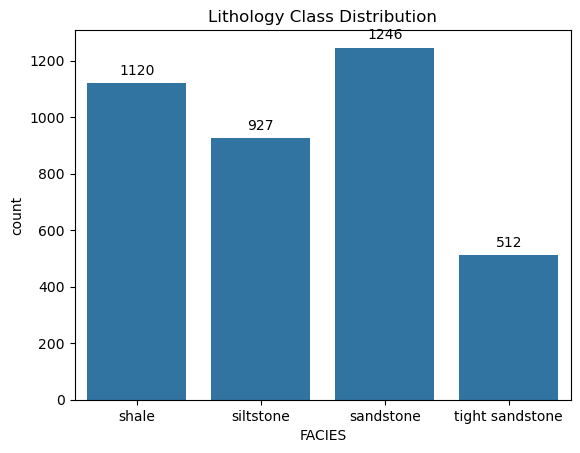


Facies Classes:
['sandstone', 'shale', 'siltstone', 'tight sandstone']

Training DenseNN...
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step
DenseNN - Acc: 0.901 | Prec: 0.902 | Rec: 0.901 | F1: 0.901

Training CNN...
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step
CNN - Acc: 0.884 | Prec: 0.884 | Rec: 0.884 | F1: 0.883

Training LSTM...
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step
LSTM - Acc: 0.843 | Prec: 0.842 | Rec: 0.843 | F1: 0.840

Training BiLSTM...
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step
BiLSTM - Acc: 0.824 | Prec: 0.820 | Rec: 0.824 | F1: 0.819

Training RNN...
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step
RNN - Acc: 0.863 | Prec: 0.862 | Rec: 0.863 | F1: 0.861

Training GRU...
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step
GRU - Acc: 0.823 | Prec: 0.819 | Rec: 0.823 | F1: 0.820

Training RESNET...
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step
RESNET - Acc: 0.887 | Prec: 0.887 | Rec: 0.887 | F1: 0.886

Training CNN-LSTM...
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
CNN-LSTM - Acc: 0.856 | Prec: 0.855 | Rec: 0.856 | F1

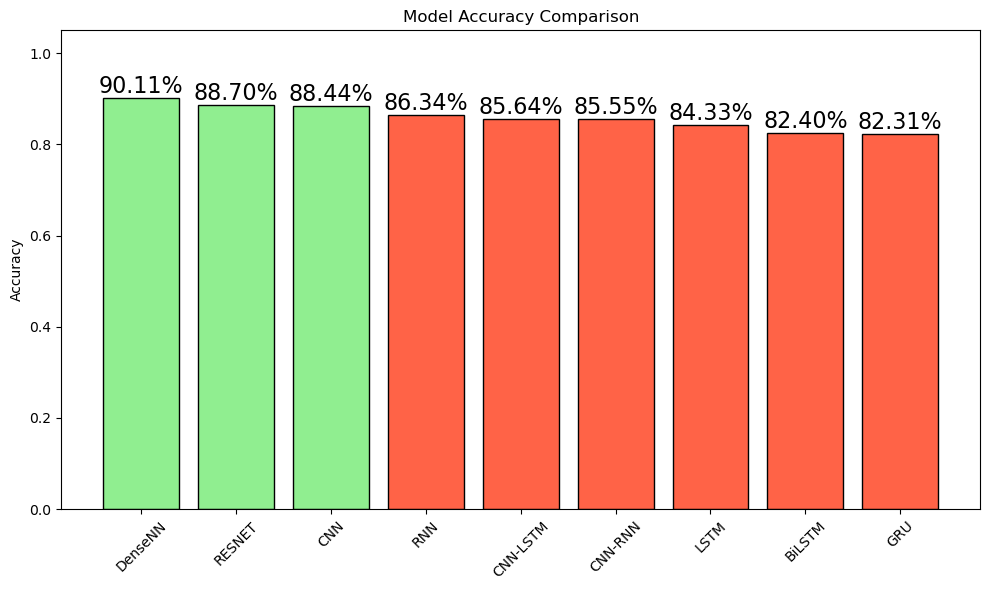

In [10]:
# ======================================================================
#  FACIES CLASSIFICATION USING DEEP LEARNING
#  COMPLETE INTEGRATED WORKFLOW 
# ======================================================================
# 0. IMPORT LIBRARIES ---
# ======================================================================
import pandas as pd
import numpy as np
import time

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import joblib

from sklearn.model_selection import (train_test_split)
from sklearn.preprocessing import (RobustScaler, LabelEncoder)

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score, cohen_kappa_score,
    matthews_corrcoef, balanced_accuracy_score
)

# --- TensorFlow / Keras ---
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Reshape, Conv1D, MaxPooling1D, Flatten, LSTM, Bidirectional, SimpleRNN, GRU, Input, Add
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

# --- scikeras wrapper for scikit-learn compatibility ---
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin
from scikeras.wrappers import KerasClassifier

# --- PDF REPORT ---
from fpdf import FPDF
import io

# ======================================================================
# 1. LOAD WELLS & CONFIGURATION
# ======================================================================
# ----------------------------------------------------------------------
# 1. DEFINE WELLS ---
# ----------------------------------------------------------------------
WELL_1_FILE = 'Well-A_processed.csv'
WELL_2_FILE = 'Well-B_processed.csv'
WELL_3_FILE = 'Well-C_processed.csv'

WELL_1 = WELL_1_FILE.split('.')[0]
WELL_2 = WELL_2_FILE.split('.')[0]
WELL_3 = WELL_3_FILE.split('.')[0]

RANDOM_STATE = 42

print(f"\nTraining Well : {WELL_1}")
print(f"Prediction Well : {WELL_2}")
print(f"Additional Training Well : {WELL_3}")


# ----------------------------------------------------------------------
# 2. LOAD DATA ---
# ----------------------------------------------------------------------
print("\nLoading Data...\n")
df_well_1 = pd.read_csv(WELL_1_FILE)
df_well_2 = pd.read_csv(WELL_2_FILE)
df_well_3 = pd.read_csv(WELL_3_FILE)

df= df_well_1
# df = pd.concat([pd.read_csv('Well-A_processed.csv'), pd.read_csv('Well-C_processed.csv')])

print(f"{WELL_1} Samples : {len(df_well_1)}")
print(f"{WELL_2} Samples : {len(df_well_2)}")
print(f"{WELL_3} Samples : {len(df_well_3)}")

# ----------------------------------------------------------------------
# 3. Visualize class distribution
# ----------------------------------------------------------------------
ax = sns.countplot(x='FACIES', data=df)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 9), 
                textcoords='offset points')
plt.title('Lithology Class Distribution')
plt.show()

# ----------------------------------------------------------------------
# 4. DEFINE FEATURES ---
# ----------------------------------------------------------------------
BASIC_FEATURES = ["GR", "RT", "RHOB", "NPHI", "DTCO", "DTSM"]
PROCESSED_FEATURES = ["VCL", "PIGN", "SUWI"]
ELASTIC_FEATURES = ["Vp", "Vs", "VpVs", "YME", "PR", "BMK", "SMG", "BI"]
FEATURE_ENGINEERING = ["GR_RT_RATIO", "VPVS_GRAD", "BI_GRAD", "FI", "RQI_ELASTIC", "SQI", "BI_PHI", "NET_RES"]

FEATURE_COLUMNS = BASIC_FEATURES + ELASTIC_FEATURES + FEATURE_ENGINEERING
TARGET_COLUMN = "FACIES"

# ----------------------------------------------------------------------
# 5. LABEL ENCODING ---
# ----------------------------------------------------------------------
label_encoder = LabelEncoder()
df_well_2['FACIES_ENCODED'] = label_encoder.fit_transform(df_well_2[TARGET_COLUMN])
df['FACIES_ENCODED'] = label_encoder.transform(df[TARGET_COLUMN])

# ----------------------------------------------------------------------
# 6. DEFINE X AND y ---
# ----------------------------------------------------------------------
X = df[FEATURE_COLUMNS]
y_encoded = df['FACIES_ENCODED']
class_names = list(label_encoder.classes_)
n_classes = len(class_names)

print("\nFacies Classes:")
print(class_names)

# ----------------------------------------------------------------------
# 7. PREPROCESSING ---
# ----------------------------------------------------------------------
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_imputed)
joblib.dump(scaler, 'well_scaler.pkl')

# ----------------------------------------------------------------------
# 8. CONVERT TARGET TO CATEGORICAL ---
# ----------------------------------------------------------------------
y_categorical = to_categorical(y_encoded, num_classes=n_classes)

# ----------------------------------------------------------------------
# 9. TRAIN TEST SPLIT ---
# ----------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_categorical, test_size=0.30,
    stratify=y_encoded, random_state=RANDOM_STATE
)
# For sequence models, reshape input
X_train_seq = X_train.reshape(-1, len(FEATURE_COLUMNS), 1)
X_test_seq = X_test.reshape(-1, len(FEATURE_COLUMNS), 1)

# ======================================================================
# 2. DEEP LEARNING MODEL DEFINITIONS
# ======================================================================
# ----------------------------------------------------------------------
# 1. Helper functions to build models
# ----------------------------------------------------------------------
input_dim = X_train.shape[1]
n_classes = y_train.shape[1]

# ----------------------------------------------------------------------
# 2. DEFINE DEEP LEARNING MODELS ---
# ----------------------------------------------------------------------
# 1. Deep Neural Network (DNN)
def build_dense_model(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.25),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 2. Convolutional Neural Network (CNN)
def build_cnn_model(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Reshape((input_dim, 1)),
        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),
        Conv1D(32, 3, activation='relu'),
        MaxPooling1D(2),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 3. Long Short-Term Memory (LSTM)
def build_lstm_model(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Reshape((input_dim, 1)),
        LSTM(64),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 4. Bi Directional Long Short-Term Memory (BiLSTM)
def build_bilstm_model(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Reshape((input_dim, 1)),
        Bidirectional(LSTM(64)),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 5. Recurrent Neural Network (RNN - SimpleRNN)
def build_rnn_model(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Reshape((input_dim, 1)),
        SimpleRNN(64),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 6. Gated Recurrent Unit (GRU)
def build_gru_model(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Reshape((input_dim, 1)),
        GRU(64),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 7. Residual Network (ResNet)
def build_resnet_block(input_tensor, units):
    x = Dense(units, activation='relu')(input_tensor)
    x = Dense(units, activation=None)(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Add()([x, input_tensor])
    x = tf.keras.layers.Activation('relu')(x)
    return x

def build_resnet_model(input_dim, n_classes):
    inputs = tf.keras.Input(shape=(input_dim,))
    x = Dense(256, activation='relu')(inputs)
    x = build_resnet_block(x, 256)
    x = build_resnet_block(x, 256)
    x = Dense(128, activation='relu')(x)
    outputs = Dense(n_classes, activation='softmax')(x)
    model = Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 8. Hybrid CNN-LSTM
def build_cnn_lstm(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Reshape((input_dim, 1)),
        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),
        LSTM(64),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 9. Hybrid CNN-RNN
def build_cnn_rnn(input_dim, n_classes):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Reshape((input_dim, 1)),
        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),
        Conv1D(32, 3, activation='relu'),
        MaxPooling1D(2),
        # Reshape for RNN
        Reshape(((input_dim // 4) - 1, 32)),
        LSTM(64),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

models = {
    'DenseNN': build_dense_model(input_dim, n_classes),
    'CNN': build_cnn_model(input_dim, n_classes),
    'LSTM': build_lstm_model(input_dim, n_classes),
    'BiLSTM': build_bilstm_model(input_dim, n_classes),
    'RNN': build_rnn_model(input_dim, n_classes),
    'GRU': build_gru_model(input_dim, n_classes),
    'RESNET': build_resnet_model(input_dim, n_classes),
    'CNN-LSTM': build_cnn_lstm(input_dim, n_classes),
    'CNN-RNN': build_cnn_rnn(input_dim, n_classes),
}

# ======================================================================
# 3. TRAIN DEEP LEARNING MODELS
# ======================================================================

# Store results
model_results = {}
pred_probs = {}
y_true_indices = np.argmax(y_test, axis=1)

# ----------------------------------------------------------------------
# 1. TRAIN MODELS PIPELINE
# ----------------------------------------------------------------------
for name, model in models.items():
    print(f"\nTraining {name}...")
    # Fit model
    model.fit(X_train, y_train, validation_split=0.3, epochs=50, verbose=0,
              callbacks=[EarlyStopping(patience=5, restore_best_weights=True)])
    # Evaluate accuracy
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    # Predict probabilities
    probs = model.predict(X_test)
    pred_probs[name] = probs
    pred_indices = np.argmax(probs, axis=1)
    # Calculate metrics
    precision = precision_score(y_true_indices, pred_indices, average='weighted')
    recall = recall_score(y_true_indices, pred_indices, average='weighted')
    f1 = f1_score(y_true_indices, pred_indices, average='weighted')
    print(f"{name} - Acc: {acc:.3f} | Prec: {precision:.3f} | Rec: {recall:.3f} | F1: {f1:.3f}")
    model_results[name] = {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1}

# ----------------------------------------------------------------------
# 2. Create performance report DataFrame ---
# ----------------------------------------------------------------------
performance_df = pd.DataFrame.from_dict(model_results, orient='index')
print("\nModel Performance Summary:")
print(performance_df)

# ----------------------------------------------------------------------
# 3. Plot histogram with top 3 models highlighted ---
# ----------------------------------------------------------------------
sorted_performance = performance_df.sort_values(by='accuracy', ascending=False)

colors = ['lightgreen' if i < 3 else 'tomato' for i in range(len(sorted_performance))]

plt.figure(figsize=(10,6))
bars = plt.bar(sorted_performance.index, sorted_performance['accuracy'], color=colors, edgecolor='black')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height*100:.2f}%', ha='center', va='bottom', fontsize=16)

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Top 3 Models for Ensemble: ['DenseNN', 'RESNET', 'CNN']

Ensemble Classification Report:
                 precision    recall  f1-score   support

      sandstone       0.92      0.93      0.92       374
          shale       0.90      0.97      0.94       336
      siltstone       0.87      0.83      0.85       278
tight sandstone       0.94      0.84      0.89       154

       accuracy                           0.90      1142
      macro avg       0.91      0.89      0.90      1142
   weighted avg       0.90      0.90      0.90      1142


Ensemble Accuracy: 0.9046

Ensemble Performance:
Accuracy              : 0.9046
Weighted F1           : 0.9037
Weighted Precision    : 0.9046
Weighted Recall       : 0.9046
Balanced Accuracy     : 0.8925
Cohen Kappa           : 0.8685
Matthews CorrCoef     : 0.8691
Log Loss              : 0.2550


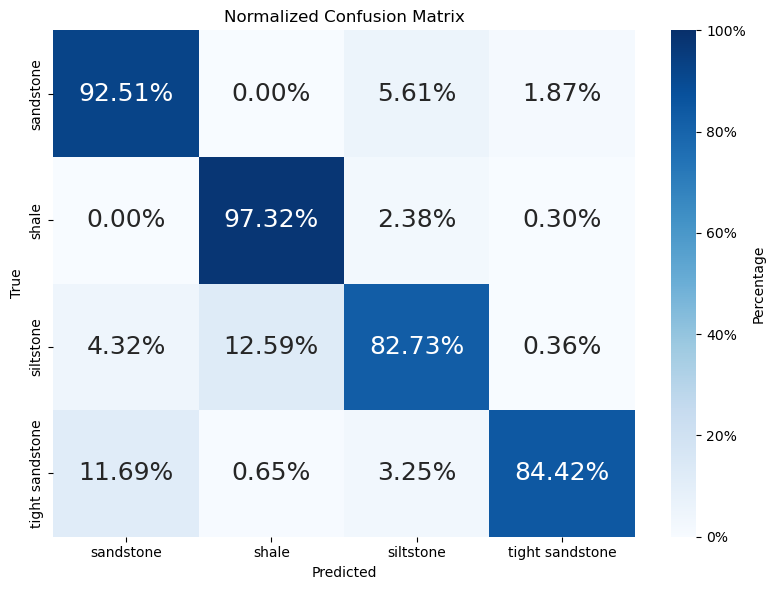

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step


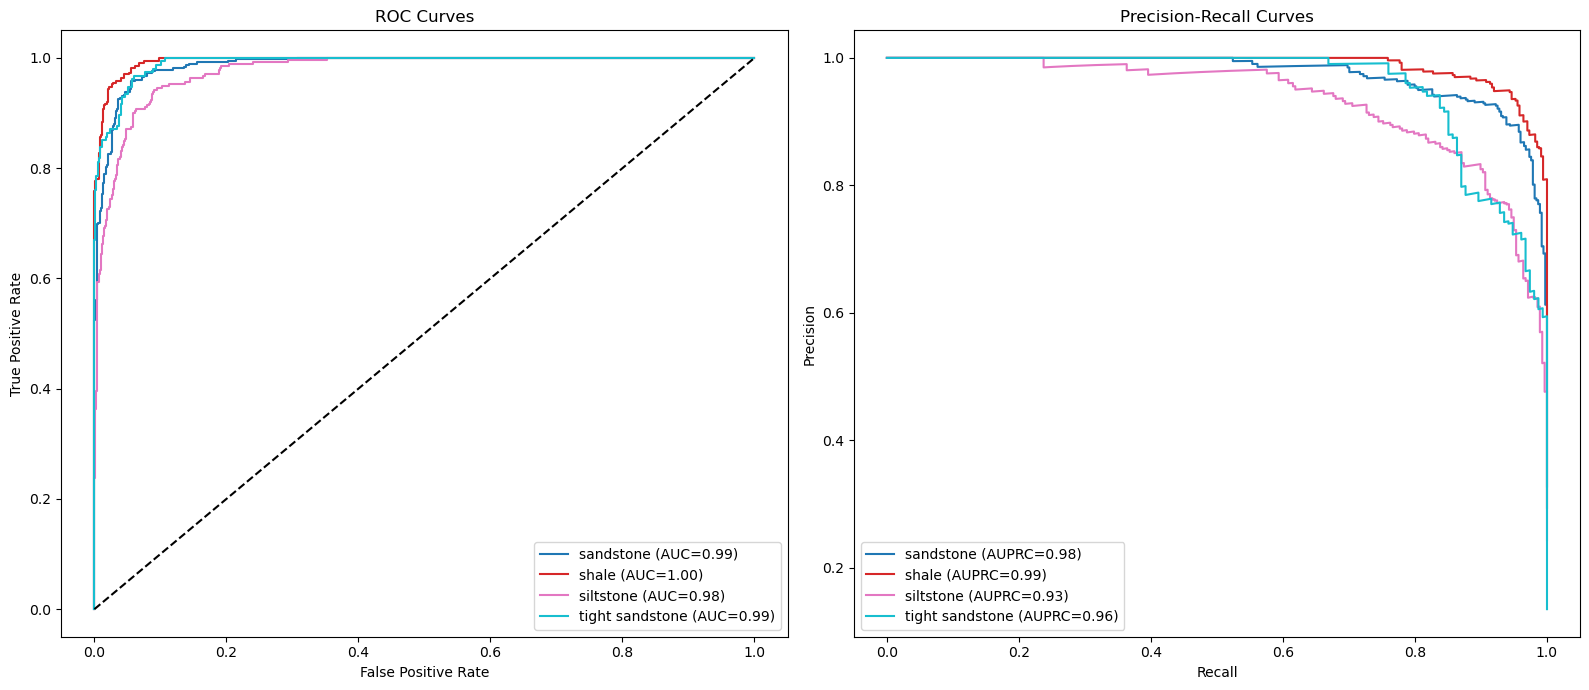


Calculating permutation importance for DenseNN...

Calculating permutation importance for RESNET...

Calculating permutation importance for CNN...


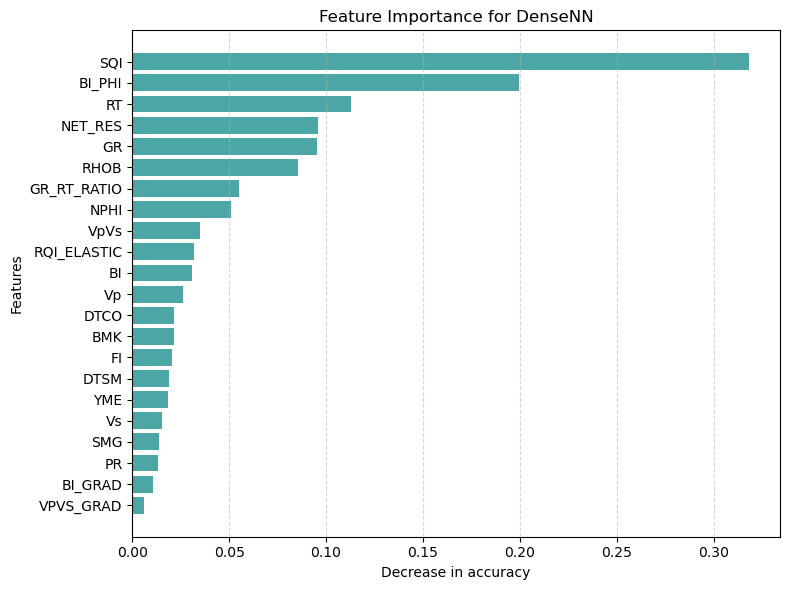

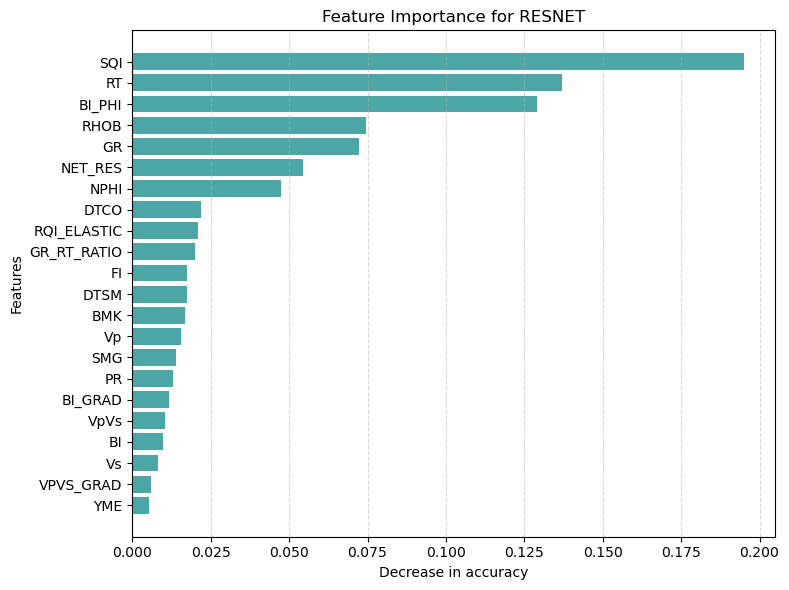

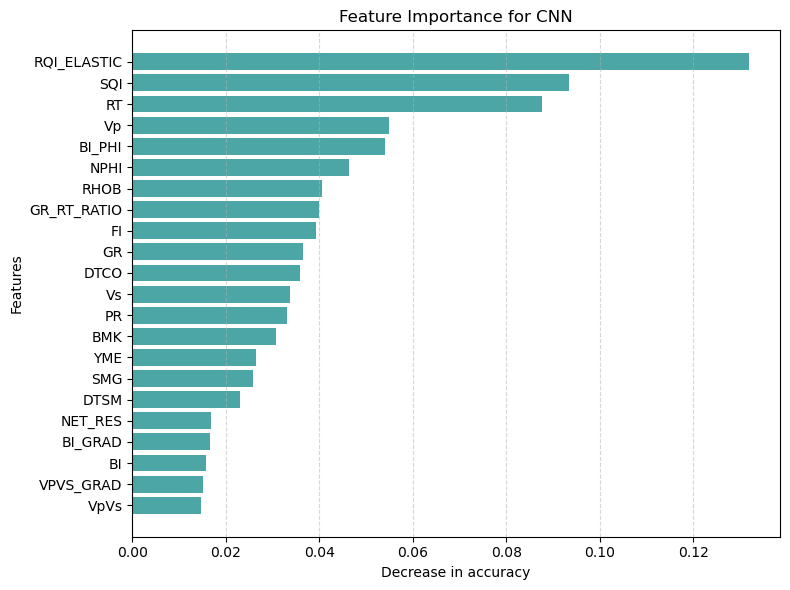


Top 5 features for DenseNN:
SQI        0.318318
BI_PHI     0.199790
RT         0.113009
NET_RES    0.095664
GR         0.095453
Name: DenseNN, dtype: float64

Top 5 features for RESNET:
SQI       0.195059
RT        0.136978
BI_PHI    0.129041
RHOB      0.074428
GR        0.072378
Name: RESNET, dtype: float64

Top 5 features for CNN:
RQI_ELASTIC    0.131932
SQI            0.093456
RT             0.087569
Vp             0.054928
BI_PHI         0.054139
Name: CNN, dtype: float64


In [11]:
# ======================================================================
# 4. ENSEMBLE ON TOP 3 MODELS & ANALYTICS WITH VISUALIZATION
# ======================================================================
# ----------------------------------------------------------------------
# 1. SORT AND SELECT TOP THREE PERFORMING MODELS
# ----------------------------------------------------------------------
top_models = list(sorted_performance.index[:3])
print(f"\nTop 3 Models for Ensemble: {top_models}")

# ----------------------------------------------------------------------
# 2. Aggregate their predicted probabilities
# ----------------------------------------------------------------------
ensemble_probs = np.mean([pred_probs[model] for model in top_models], axis=0)
ensemble_pred_indices = np.argmax(ensemble_probs, axis=1)

# ----------------------------------------------------------------------
# 3. Map to original class labels
# ----------------------------------------------------------------------
true_labels = label_encoder.inverse_transform(y_true_indices)
ensemble_pred_labels = label_encoder.inverse_transform(ensemble_pred_indices)

# ----------------------------------------------------------------------
# 4. Classification Report
# ----------------------------------------------------------------------
print("\nEnsemble Classification Report:")
print(classification_report(true_labels, ensemble_pred_labels, target_names=class_names))

# ----------------------------------------------------------------------
# 5. Compute accuracy
# ----------------------------------------------------------------------
ensemble_accuracy = np.mean(ensemble_pred_indices == y_true_indices)
print(f"\nEnsemble Accuracy: {ensemble_accuracy:.4f}")

# ----------------------------------------------------------------------
# 6. Recompute metrics
# ----------------------------------------------------------------------
ensemble_precision = precision_score(y_true_indices, ensemble_pred_indices, average='weighted')
ensemble_recall = recall_score(y_true_indices, ensemble_pred_indices, average='weighted')
ensemble_f1 = f1_score(y_true_indices, ensemble_pred_indices, average='weighted')
ensemble_kappa = cohen_kappa_score(y_true_indices, ensemble_pred_indices)
ensemble_mcc = matthews_corrcoef(y_true_indices, ensemble_pred_indices)
ensemble_balanced_acc = balanced_accuracy_score(y_true_indices, ensemble_pred_indices)
ensemble_log_loss = tf.keras.losses.CategoricalCrossentropy()(y_test, ensemble_probs).numpy()

# ----------------------------------------------------------------------
# 6. Print Complete Analytics - Ensemble Model Performance
# ----------------------------------------------------------------------
print(f"\nEnsemble Performance:")
print(f"Accuracy              : {ensemble_accuracy:.4f}")
print(f"Weighted F1           : {ensemble_f1:.4f}")
print(f"Weighted Precision    : {ensemble_precision:.4f}")
print(f"Weighted Recall       : {ensemble_recall:.4f}")
print(f"Balanced Accuracy     : {ensemble_balanced_acc:.4f}")
print(f"Cohen Kappa           : {ensemble_kappa:.4f}")
print(f"Matthews CorrCoef     : {ensemble_mcc:.4f}") 
print(f"Log Loss              : {ensemble_log_loss:.4f}")

# ----------------------------------------------------------------------
# 8. CONFUSION MATRIX
# ----------------------------------------------------------------------
cm = confusion_matrix(y_true_indices, ensemble_pred_indices)

# Normalize each row safely (rows with a sum of zero remain zero)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
cm_percent = cm_norm * 100

annotations = [
        [f"{value:.2f}%" for value in row]
        for row in cm_percent
    ]

plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    cm_percent,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 18},
    cbar_kws={"label": "Percentage"}
)

# Format color-bar ticks as percentages
colorbar = ax.collections[0].colorbar
colorbar.set_ticks([0, 20, 40, 60, 80, 100])
colorbar.set_ticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])


plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()
plt.close()

# ----------------------------------------------------------------------
# 8. ROC and PR Curves ---
# ----------------------------------------------------------------------
# Compute predictions for each top model
all_preds = []
for name in top_models:
    preds = models[name].predict(X_test)
    all_preds.append(preds)

# Calculate weighted average probabilities
weighted_probs = np.mean(all_preds, axis=0)

# Set up colors
colors = plt.get_cmap('tab10', n_classes)

# Plot ROC and PR curves
fig, axes = plt.subplots(1, 2, figsize=(16,7))
ax_roc, ax_pr = axes

# ROC Curves
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test[:, i], weighted_probs[:, i])
    roc_auc_value = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, label=f'{class_names[i]} (AUC={roc_auc_value:.2f})', color=colors(i))
ax_roc.plot([0,1], [0,1], 'k--')
ax_roc.set_title('ROC Curves')
ax_roc.set_xlabel('False Positive Rate')
ax_roc.set_ylabel('True Positive Rate')
ax_roc.legend()

# PR Curves
for i in range(n_classes):
    precision, recall, _ = precision_recall_curve(y_test[:, i], weighted_probs[:, i])
    pr_auc = average_precision_score(y_test[:, i], weighted_probs[:, i])
    ax_pr.plot(recall, precision, label=f'{class_names[i]} (AUPRC={pr_auc:.2f})', color=colors(i))
ax_pr.set_title('Precision-Recall Curves')
ax_pr.set_xlabel('Recall')
ax_pr.set_ylabel('Precision')
ax_pr.legend()

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 9. Compute Feature/Permutation Importance and Visualization
# ----------------------------------------------------------------------
class KerasWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, model):
        self.model = model
    def fit(self, X, y=None):
        # Already trained
        return self
    def predict(self, X):
        return np.argmax(self.model.predict(X), axis=1)
    def score(self, X, y):
        # Evaluate returns [loss, accuracy]
        return self.model.evaluate(X, y, verbose=0)[1]

# Compute permutation importance for top models
importances_dict = {}
top_3_model_names = list(sorted_performance.index[:3])

for name in top_3_model_names:
    print(f"\nCalculating permutation importance for {name}...")
    wrapped_model = KerasWrapper(models[name])
    r = permutation_importance(
        wrapped_model, X_scaled, y_categorical,
        n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
    )
    importances_dict[name] = r.importances_mean

# Feature Importance Visualization ---
importances_df = pd.DataFrame(importances_dict, index=FEATURE_COLUMNS)

for name in importances_df.columns:
    importance_series = importances_df[name].sort_values(ascending=True)
    plt.figure(figsize=(8,6))
    plt.barh(importance_series.index, importance_series.values, color='teal', alpha=0.7)
    plt.title(f"Feature Importance for {name}")
    plt.xlabel("Decrease in accuracy")
    plt.ylabel("Features")
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Display Top 5 features per model ---
for name in importances_df.columns:
    print(f"\nTop 5 features for {name}:")
    print(importances_df[name].sort_values(ascending=False).head(5))

Retraining DenseNN on full dataset...
Retraining RESNET on full dataset...
Retraining CNN on full dataset...

Retraining complete. Proceeding to ensemble analytics.
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step

### Final Ensemble Classification Report (Full Data) ###
                 precision    recall  f1-score   support

      sandstone       0.97      0.99      0.98      1246
          shale       0.95      1.00      0.97      1120
      siltstone       0.98      0.94      0.96       927
tight sandstone       0.99      0.93      0.96       512

       accuracy                           0.97      3805
      macro avg       0.97      0.96      0.97      3805
   weighted avg       0.97      0.97      0.97      3805



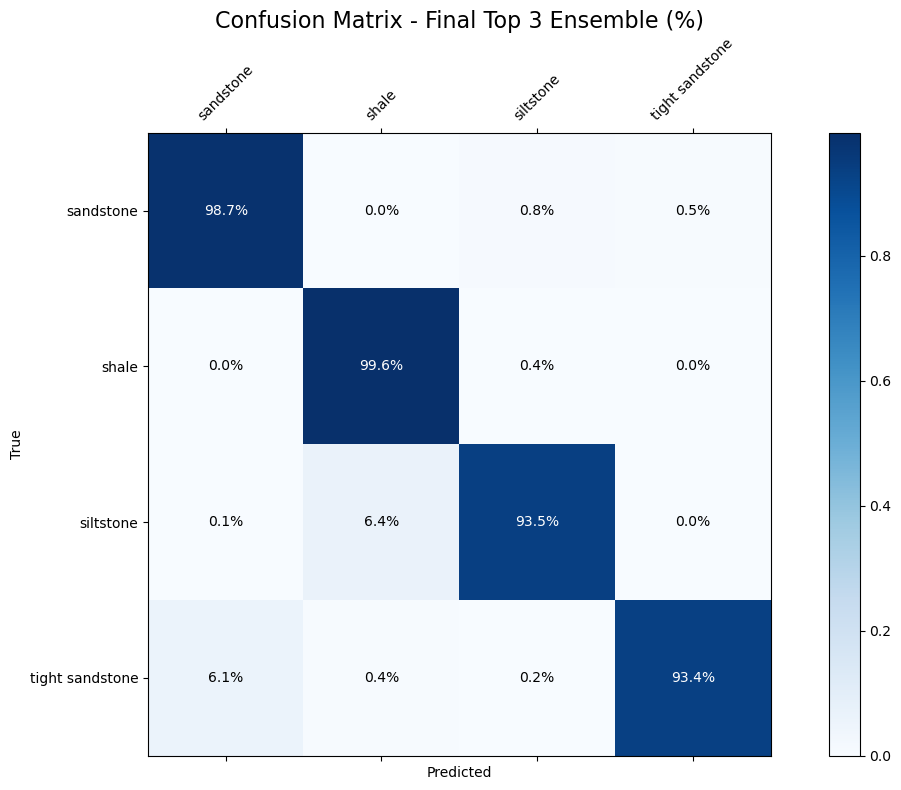

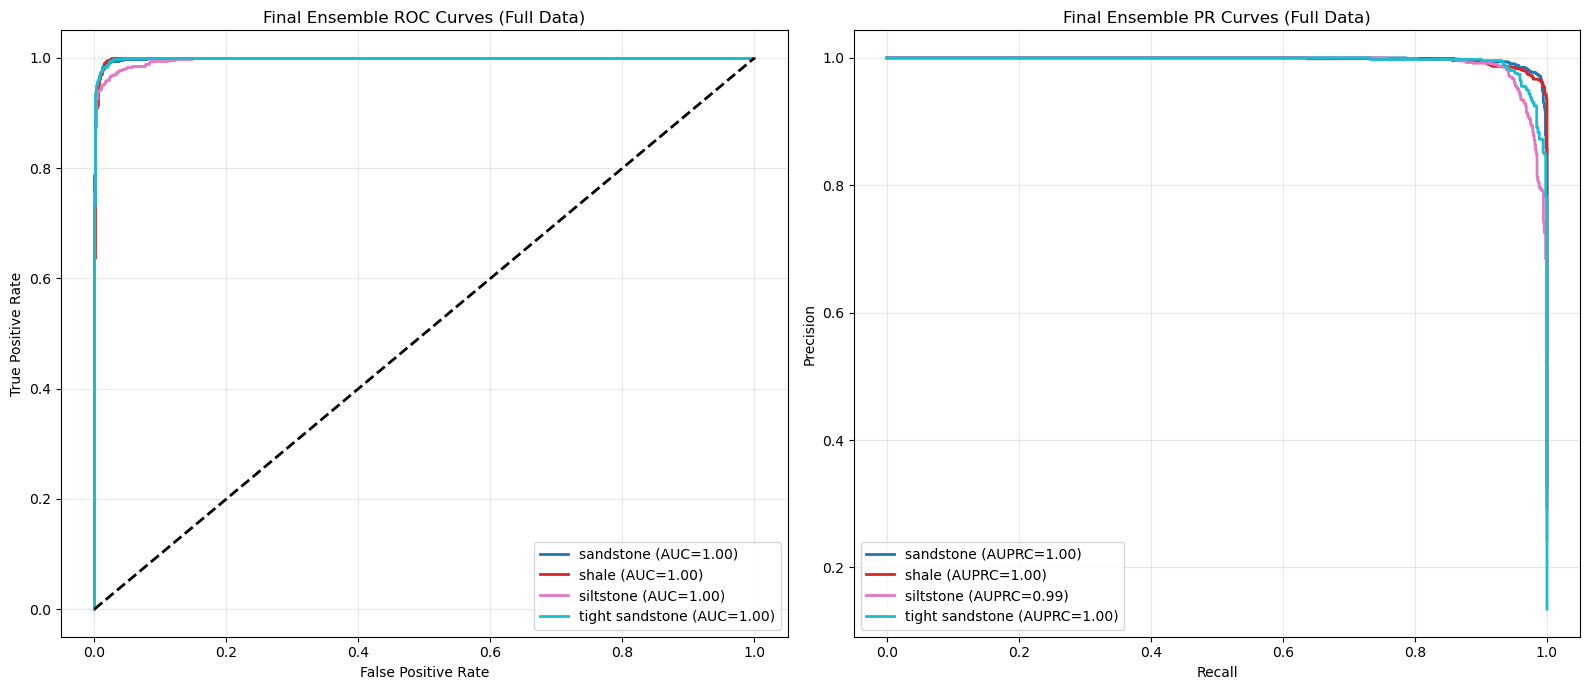

In [12]:
# ======================================================================
# 5. COMPLETE WELL MODELING ON TOP 3 MODELS & ANALYTICS WITH VISUALIZATION
# ======================================================================
# ----------------------------------------------------------------------
# 1. Build Deep Learning Model List
# ----------------------------------------------------------------------
builder_map = {
    'DenseNN': build_dense_model,
    'CNN': build_cnn_model,
    'LSTM': build_lstm_model,
    'BiLSTM': build_bilstm_model,
    'RNN': build_rnn_model,
    'GRU': build_gru_model,
    'RESNET': build_resnet_model,
    'CNN-LSTM': build_cnn_lstm,
    'CNN-RNN': build_cnn_rnn,
}
best_models_list = top_3_model_names

# ----------------------------------------------------------------------
# 2. Retrain Best 3 Models on Full Dataset
# ----------------------------------------------------------------------
final_models = {}
for name in best_models_list:
    print(f"Retraining {name} on full dataset...")
    # Access the function reference from the map
    builder_func = builder_map[name]
    # Now call it with your dimensions
    model = builder_func(input_dim, n_classes)
    
    # Optional: pass class_weights here if your model supports it
    model.fit(X_scaled, y_categorical, epochs=50, batch_size=32, verbose=0)
    final_models[name] = model

print("\nRetraining complete. Proceeding to ensemble analytics.")

# ----------------------------------------------------------------------
# 3. Generate Ensemble Predictions on Full Dataset
# ----------------------------------------------------------------------
# Using simple averaging for the top 3
final_preds = np.array([final_models[name].predict(X_scaled) for name in best_models_list])
final_ensemble_prob = np.mean(final_preds, axis=0)
final_ensemble_pred = np.argmax(final_ensemble_prob, axis=1)

# ----------------------------------------------------------------------
# 4. Final Analytics
# ----------------------------------------------------------------------
print("\n### Final Ensemble Classification Report (Full Data) ###")
print(classification_report(df['FACIES_ENCODED'], final_ensemble_pred, zero_division=0, target_names=label_encoder.classes_))

# ----------------------------------------------------------------------
# 5. Final Confusion Matrix
# ----------------------------------------------------------------------
cm = confusion_matrix(df['FACIES_ENCODED'], final_ensemble_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, None]
cm_norm[np.isnan(cm_norm)] = 0

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(12, 8))
cax = ax.matshow(cm_norm, cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Final Top 3 Ensemble (%)", fontsize=16)
fig.colorbar(cax)
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xticklabels(class_names, rotation=45)
ax.set_yticklabels(class_names)

for i in range(n_classes):
    for j in range(n_classes):
        ax.text(j, i, f"{cm_norm[i,j]*100:.1f}%", ha='center', va='center', color='white' if cm_norm[i,j] > 0.5 else 'black')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"DLN_confusion_matrix_final_{WELL_1}.png", dpi=300, bbox_inches='tight')
plt.show()

# ----------------------------------------------------------------------
# 6. Combined ROC and PR Curves
# ----------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
# Initialize colors for each facies class
colors = plt.colormaps['tab10'].resampled(n_classes)
# Iterate through each class to plot its specific performance
for i in range(n_classes):
    # ROC Calculation
    fpr, tpr, _ = roc_curve(y_categorical[:, i], final_ensemble_prob[:, i])
    roc_auc_value = auc(fpr, tpr)
    ax1.plot(fpr, tpr, color=colors(i), lw=2, 
             label=f'{class_names[i]} (AUC={roc_auc_value:.2f})')
    
    # PR Calculation
    precision, recall, _ = precision_recall_curve(y_categorical[:, i], final_ensemble_prob[:, i])
    auprc_value = average_precision_score(y_categorical[:, i], final_ensemble_prob[:, i])
    ax2.plot(recall, precision, color=colors(i), lw=2, 
             label=f'{class_names[i]} (AUPRC={auprc_value:.2f})')

# Formatting ROC Plot
ax1.plot([0, 1], [0, 1], 'k--', lw=2)
ax1.set_title('Final Ensemble ROC Curves (Full Data)')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)

# Formatting PR Plot
ax2.set_title('Final Ensemble PR Curves (Full Data)')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend(loc="lower left")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

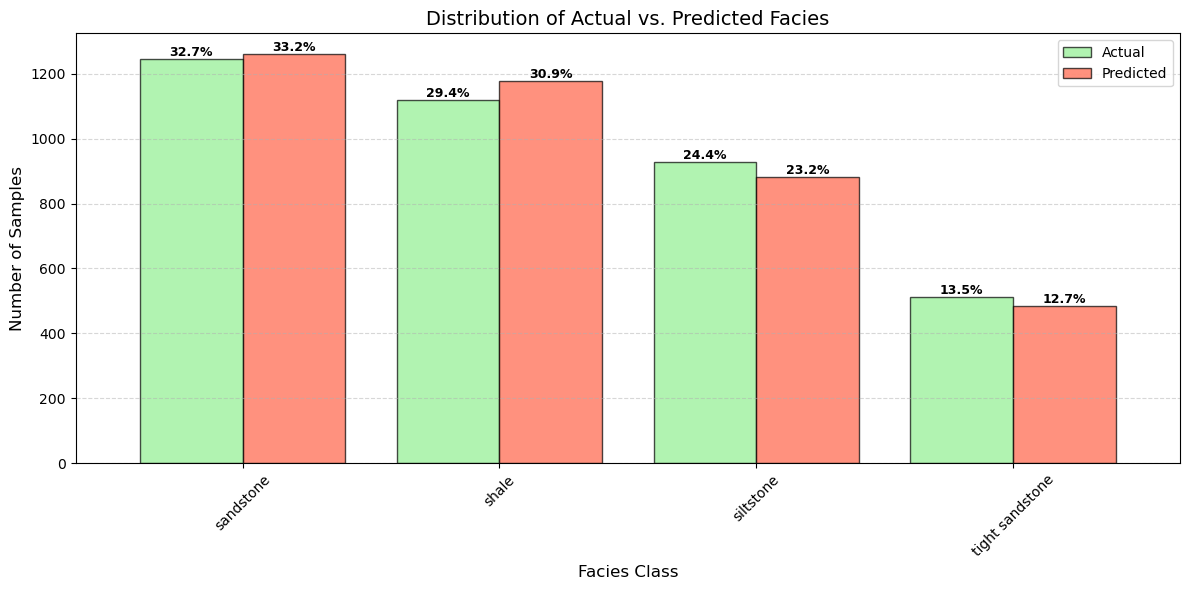

In [13]:
# ----------------------------------------------------------------------
# 7. Compute comparison between Facies and Predicted Facies
# ----------------------------------------------------------------------
y_true_labels = df['FACIES_ENCODED']
y_pred_labels = final_ensemble_pred

# Count occurrences
actual_counts = pd.Series(y_true_labels).value_counts().sort_index()
pred_counts = pd.Series(y_pred_labels).value_counts().sort_index()

# Create a DataFrame for easy plotting
comparison_df = pd.DataFrame({'Actual': actual_counts, 'Predicted': pred_counts})

# Create a grouped bar chart
ax = comparison_df.plot(kind='bar', figsize=(12, 6), color=['lightgreen', 'tomato'], alpha=0.7, edgecolor='black', width=0.8)

plt.title("Distribution of Actual vs. Predicted Facies", fontsize=14)
plt.xlabel("Facies Class", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)
plt.xticks(ticks=range(len(label_encoder.classes_)), labels=label_encoder.classes_, rotation=45)

def add_labels(ax):
    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        x, y = p.get_xy() 
        # Calculate percentage relative to total samples
        total_samples = len(y_true_labels)
        percentage = (height / total_samples) * 100
        
        ax.annotate(f'{percentage:.1f}%', (x + width/2, y + height), 
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

add_labels(ax)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [14]:
# ======================================================================
# 6. PREDICTION IN WELL - 2
# ======================================================================
# ----------------------------------------------------------------------
# 1. PREPROCESS WELL 2 DATA
# ----------------------------------------------------------------------
scaler = joblib.load('well_scaler.pkl')
X_well2_scaled = scaler.transform(df_well_2[FEATURE_COLUMNS].values)

# ----------------------------------------------------------------------
# 2. GENERATE ENSEMBLE PREDICTIONS
# ----------------------------------------------------------------------
well2_preds = []
for name in best_models_list:
    model = final_models[name]
    pred = model.predict(X_well2_scaled)
    well2_preds.append(pred)

well2_ensemble_prob = np.mean(well2_preds, axis=0)
well2_ensemble_pred = np.argmax(well2_ensemble_prob, axis=1)

# ----------------------------------------------------------------------
# 3. CONVERT TO CLASS LABELS
# ----------------------------------------------------------------------
well2_facies = label_encoder.inverse_transform(well2_ensemble_pred)

# ----------------------------------------------------------------------
# 4. APPEND TO WELL 2 DATAFRAME
# ----------------------------------------------------------------------
df_well_2['PREDICTED_FACIES'] = well2_facies
df_well_2['PREDICTED_PROBABILITY'] = np.max(well2_ensemble_prob, axis=1)

# ----------------------------------------------------------------------
# 5. SAVE PREDICTIONS AND EXPORT
# ----------------------------------------------------------------------
df_well_2.to_csv("Well_2_Predictions.csv", index=False)
print("Well 2 predictions saved to 'Well_2_Predictions.csv'")

135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Well 2 predictions saved to 'Well_2_Predictions.csv'



### Well 2 Classification Report ###
                 precision    recall  f1-score   support

      sandstone       0.75      0.60      0.67      1644
          shale       0.82      0.98      0.89      1427
      siltstone       0.25      0.38      0.30       557
tight sandstone       0.89      0.56      0.69       669

       accuracy                           0.69      4297
      macro avg       0.68      0.63      0.64      4297
   weighted avg       0.73      0.69      0.70      4297



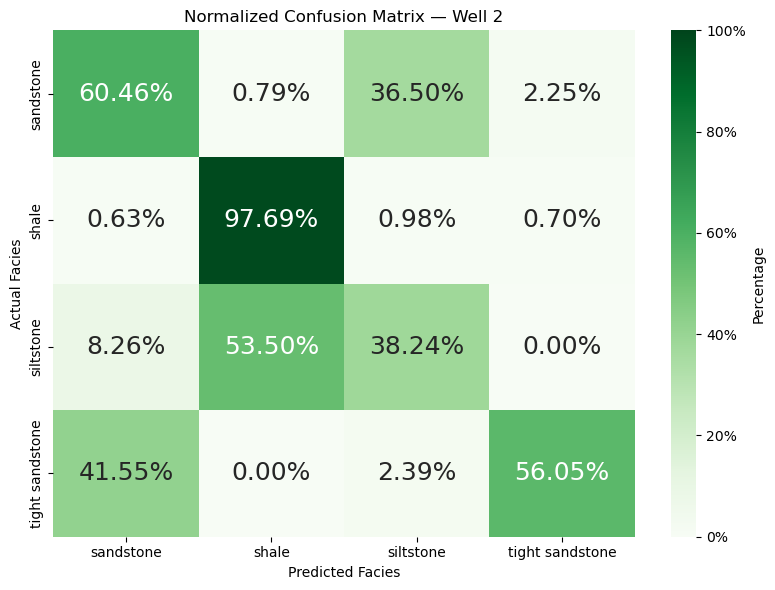

135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


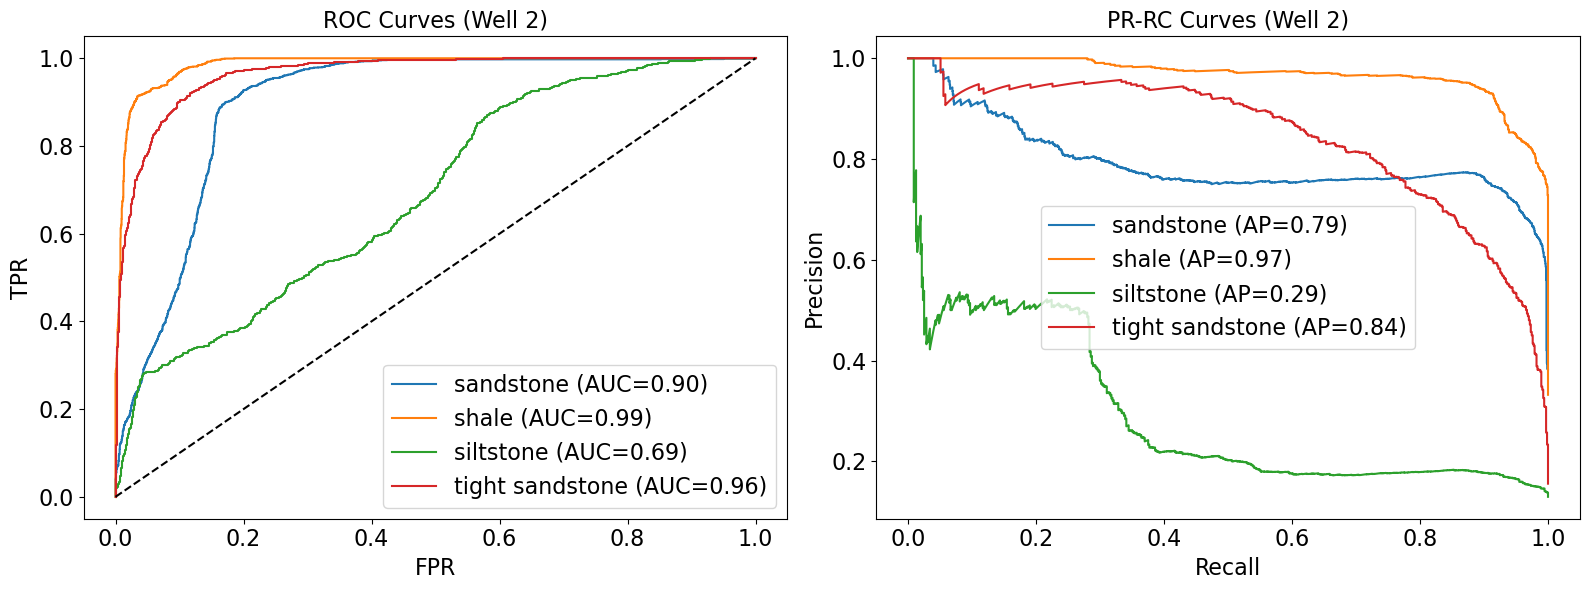

In [15]:
# Convert encoded ground truth to string labels.
y_true_strings = label_encoder.inverse_transform(
    df_well_2["FACIES_ENCODED"].to_numpy().astype(int)
)
y_pred_strings = df_well_2["PREDICTED_FACIES"].to_numpy()

print("\n### Well 2 Classification Report ###")
print(
    classification_report(
        y_true_strings,
        y_pred_strings,
        labels=class_names,
        target_names=class_names,
        zero_division=0,
    )
)

# Confusion matrix in the same class order as the encoder.
cm_well2 = confusion_matrix(
    y_true_strings,
    y_pred_strings,
    labels=class_names,
)

# Normalize each row; rows with no samples remain zero.
row_sums = cm_well2.sum(axis=1, keepdims=True)
cm_norm = np.divide(
    cm_well2.astype(float),
    row_sums,
    out=np.zeros_like(cm_well2, dtype=float),
    where=row_sums != 0,
)
cm_percent = cm_norm * 100

annotations = np.array(
    [[f"{value:.2f}%" for value in row] for row in cm_percent]
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm_percent,
    annot=annotations,
    fmt="",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 18},
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percentage"},
    ax=ax,
)

colorbar = ax.collections[0].colorbar
colorbar.set_ticks([0, 20, 40, 60, 80, 100])
colorbar.set_ticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])

ax.set_title("Normalized Confusion Matrix — Well 2")
ax.set_xlabel("Predicted Facies")
ax.set_ylabel("Actual Facies")
plt.tight_layout()
plt.show()
plt.close(fig)

from sklearn.preprocessing import label_binarize
# 1. Generate probabilities for each of the top 3 models on Well 2
well2_model_preds = []
for name in best_models_list:
    # Predict on Well 2 data
    prob = final_models[name].predict(X_well2_scaled)
    well2_model_preds.append(prob)

# 2. Average them to get the ensemble probability
final_ensemble_prob_well2 = np.mean(well2_model_preds, axis=0)

# Binarize the labels for multi-class ROC/PRC
y_test_bin = label_binarize(df_well_2['FACIES_ENCODED'], classes=range(n_classes))
y_prob_well2 = final_ensemble_prob_well2 # Ensure you have this from your predict method

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for i in range(n_classes):
    # ROC
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_well2[:, i])
    ax1.plot(fpr, tpr, label=f'{label_encoder.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
    
    # PR-RC
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_prob_well2[:, i])
    ax2.plot(recall, precision, label=f'{label_encoder.classes_[i]} (AP={average_precision_score(y_test_bin[:, i], y_prob_well2[:, i]):.2f})')

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set(title='ROC Curves (Well 2)', xlabel='FPR', ylabel='TPR')
ax2.set(title='PR-RC Curves (Well 2)', xlabel='Recall', ylabel='Precision')

for ax in (ax1, ax2):
    ax.title.set_fontsize(16)
    ax.xaxis.label.set_size(16)
    ax.yaxis.label.set_size(16)
    ax.tick_params(axis='both', labelsize=16)
    ax.legend(fontsize=16)


plt.tight_layout()
plt.show()

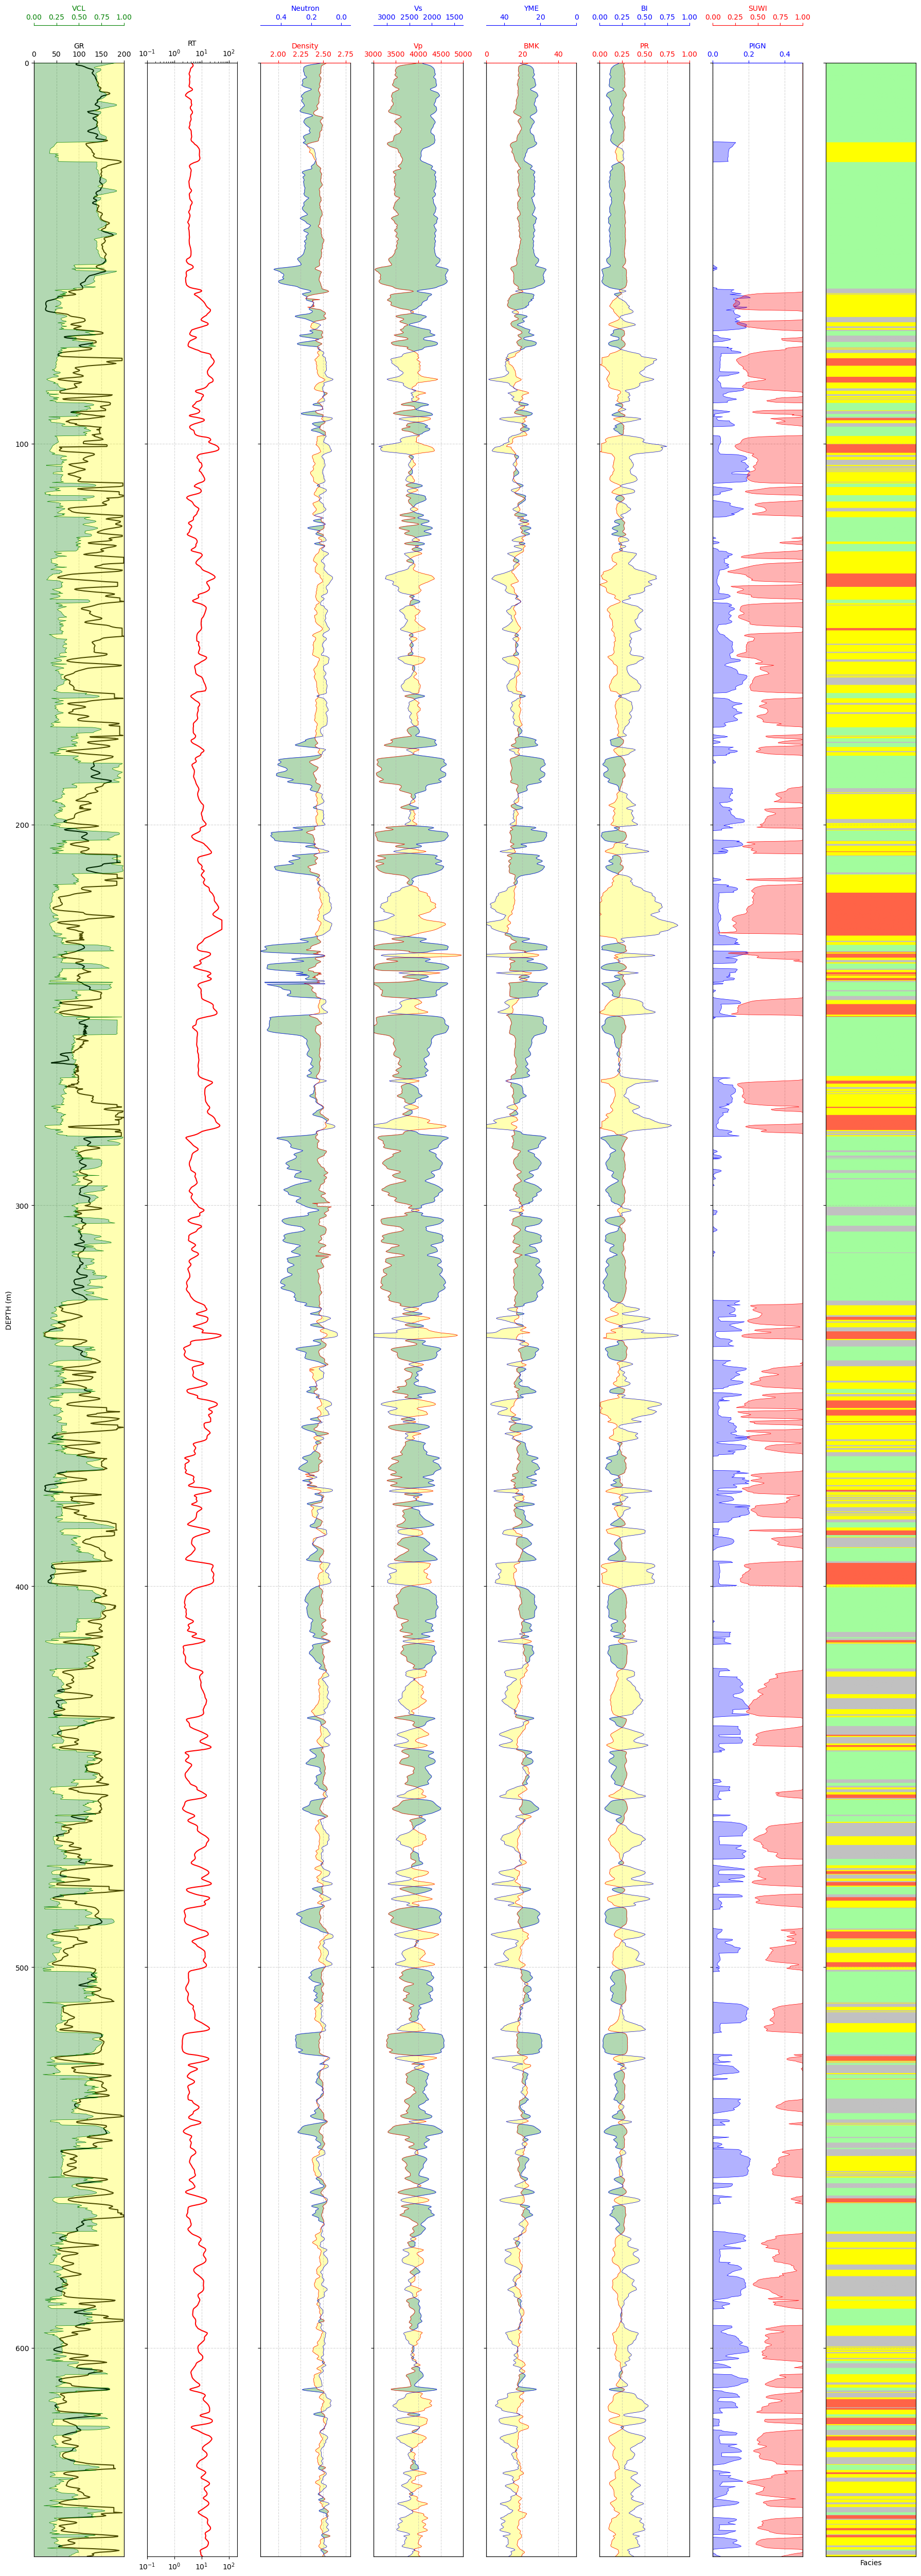

In [16]:

def plot_elastic_multitrack(df_well_2, depth_col="DEPTH", gr_col="GR", facies_col="PREDICTED_FACIES"):
    # --- Data Prep ---
    facies_categories = ['Sandstone', 'Shale', 'Siltstone', 'Tight sandstone']
    lithology_numbers = {
        0: {'lith': 'Sandstone', 'hatch': '..', 'color': '#ffff00'},
        1: {'lith': 'Shale', 'hatch': '--', 'color': '#A2FD9D'},
        2: {'lith': 'Siltstone', 'hatch': 'xx', 'color': '#c1c1c1'},
        3: {'lith': 'Tight Sandstone', 'hatch': '///', 'color': '#ff6347'}
    }
    
    df_well_2[facies_col] = df_well_2[facies_col].str.lower()
    facies_mapping = {name.lower(): i for i, name in enumerate(facies_categories)}
    df_well_2['facies_code'] = df_well_2[facies_col].map(facies_mapping).fillna(-1).astype(int)

    cmap = mcolors.ListedColormap([lithology_numbers[i]['color'] for i in range(len(facies_categories))])
    
    depth = df_well_2[depth_col]
    fig, axes = plt.subplots(nrows=1, ncols=8, figsize=(18, 50), sharey=True)
    
    # --- Common Formatting ---
    for ax in axes:
        ax.set_ylim(depth.max(), depth.min())
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)

    # Helper function to enable top/bottom ticks on secondary (twin) axes
    def enable_twin_ticks(ax):
        ax.tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)
        # Ensure the twin axis spine is correctly positioned at the top
        ax.spines["top"].set_position(("axes", 1.0))

    # --- Tracks 2 & 4 (Cross-over fills) ---
    def add_crossover(ax, ax_twin, col1, col2, color_pos, color_neg):
        x1 = df_well_2[col1]
        x2 = df_well_2[col2]
        # Normalize to common plot space
        ax_lim = ax.get_xlim()
        twin_lim = ax_twin.get_xlim()
        
        # Scaling logic for crossover
        x2_norm = ((x2 - twin_lim[0]) / (twin_lim[1] - twin_lim[0])) * (ax_lim[1] - ax_lim[0]) + ax_lim[0]
        ax.fill_betweenx(depth, x1, x2_norm, where=x1 >= x2_norm, color=color_pos, interpolate=True, alpha=0.3)
        ax.fill_betweenx(depth, x1, x2_norm, where=x1 <= x2_norm, color=color_neg, interpolate=True, alpha=0.3)

    axes[0].set_ylabel(f"{depth_col} (m)")
    
    # Track 1: GR / VCL
    axes[0].plot(df_well_2[gr_col], depth, color="black")
    axes[0].set_xlim(0, 200)
    axes[0].set_xlabel("GR")
    axes[0].xaxis.label.set_color("black")
    axes[0].tick_params(axis='x', colors="black")
    axes[0].spines["top"].set_edgecolor("black")
    ax1 = axes[0].twiny()

    ax1.plot(df_well_2["VCL"], depth, color='green', lw=0.5)
    ax1.set_xlim(0, 1)
    ax1.set_xlabel('VCL')
    ax1.xaxis.label.set_color("green")
    ax1.spines["top"].set_position(("axes", 1.015))
    ax1.tick_params(axis='x', colors="green")
    ax1.spines["top"].set_edgecolor("green")

    ax1.fill_betweenx(df_well_2['DEPTH'], df_well_2['VCL'], 0, facecolor='green', alpha=0.3)
    ax1.fill_betweenx(df_well_2['DEPTH'], df_well_2['VCL'], 1, facecolor='yellow', alpha=0.3)

    for ax in [axes[0], ax1]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 2: RT
    axes[1].semilogx( df_well_2["RT"], depth, color="red")
    axes[1].set_xlim(0.1, 200)
    axes[1].set_xlabel("RT")
    axes[1].xaxis.set_ticks_position("top")
    axes[1].xaxis.set_label_position("top")
    axes[1].tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)

    # Track 3: RHOB/NPHI
    ax3 = axes[2].twiny()
    axes[2].plot(df_well_2["RHOB"], depth, color='red', lw=0.5)
    axes[2].set_xlim(1.8, 2.8)
    axes[2].set_xlabel('Density')
    axes[2].xaxis.label.set_color("red")
    axes[2].tick_params(axis='x', colors="red")
    axes[2].spines["top"].set_edgecolor("red")

    ax3.plot(df_well_2["NPHI"], depth, color='blue', lw=0.5)
    ax3.set_xlim(0.54, -0.06)
    ax3.set_xlabel('Neutron')
    ax3.xaxis.label.set_color("blue")
    ax3.spines["top"].set_position(("axes", 1.015))
    ax3.tick_params(axis='x', colors="blue")
    ax3.spines["top"].set_edgecolor("blue")

    add_crossover(axes[2], ax3, "RHOB", "NPHI", "green", "yellow")
    for ax in [axes[2], ax3]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 4: Vp/Vs
    ax4 = axes[3].twiny()
    axes[3].plot(df_well_2["Vp"], depth, color='red', lw=0.5)
    axes[3].set_xlim(3000, 5000)
    axes[3].set_xlabel('Vp')
    axes[3].xaxis.label.set_color("red")
    axes[3].tick_params(axis='x', colors="red")
    axes[3].spines["top"].set_edgecolor("red")

    ax4.plot(df_well_2["Vs"], depth, color='blue', lw=0.5)
    ax4.set_xlim(3300, 1300)
    ax4.set_xlabel('Vs')
    ax4.xaxis.label.set_color("blue")
    ax4.spines["top"].set_position(("axes", 1.015))
    ax4.tick_params(axis='x', colors="blue")
    ax4.spines["top"].set_edgecolor("blue")

    add_crossover(axes[3], ax4, "Vp", "Vs", "yellow", "green")
    for ax in [axes[3], ax4]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")

    # Track 5: Young's Modulus and BMK
    ax5 = axes[4].twiny()
    axes[4].plot(df_well_2["BMK"], depth, color='red', lw=0.5)
    axes[4].set_xlim(0, 50)
    axes[4].set_xlabel('BMK')
    axes[4].xaxis.label.set_color("red")
    axes[4].tick_params(axis='x', colors="red")
    axes[4].spines["top"].set_edgecolor("red")

    ax5.plot(df_well_2["YME"], depth, color='blue', lw=0.5)
    ax5.set_xlim(50, 0)
    ax5.set_xlabel('YME')
    ax5.xaxis.label.set_color("blue")
    ax5.spines["top"].set_position(("axes", 1.015))
    ax5.tick_params(axis='x', colors="blue")
    ax5.spines["top"].set_edgecolor("blue")
    add_crossover(axes[4], ax5, "BMK", "YME", "yellow", "green")
    
    for ax in [axes[4], ax5]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")

    # Track 6: PR and BI
    ax6 = axes[5].twiny()
    axes[5].plot(df_well_2["PR"], depth, color='red', lw=0.5)
    axes[5].set_xlim(0, 1)
    axes[5].set_xlabel('PR')
    axes[5].xaxis.label.set_color("red")
    axes[5].tick_params(axis='x', colors="red")
    axes[5].spines["top"].set_edgecolor("red")

    ax6.plot(df_well_2["BI"], depth, color='blue', lw=0.5)
    ax6.set_xlim(0, 1)
    ax6.set_xlabel('BI')
    ax6.xaxis.label.set_color("blue")
    ax6.spines["top"].set_position(("axes", 1.015))
    ax6.tick_params(axis='x', colors="blue")
    ax6.spines["top"].set_edgecolor("blue")
    add_crossover(axes[5], ax6, "PR", "BI", "green", "yellow")

    for ax in [axes[5], ax6]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 7: PIGN Sw
    ax7 = axes[6].twiny()
    axes[6].plot(df_well_2["PIGN"], depth, color='blue', lw=0.5)
    axes[6].set_xlim(0, 0.5)
    axes[6].set_xlabel('PIGN')
    axes[6].xaxis.label.set_color("blue")
    axes[6].tick_params(axis='x', colors="blue")
    axes[6].spines["top"].set_edgecolor("blue")

    ax7.plot((1-df_well_2["SUWI"]), depth, color='red', lw=0.5)
    ax7.set_xlim(0, 1)
    ax7.set_xlabel('SUWI')
    ax7.xaxis.label.set_color("red")
    ax7.spines["top"].set_position(("axes", 1.015))
    ax7.tick_params(axis='x', colors="red")
    ax7.spines["top"].set_edgecolor("red")

    axes[6].fill_betweenx(df_well_2['DEPTH'], df_well_2['PIGN'], 0, facecolor='blue', alpha=0.3)
    ax7.fill_betweenx(df_well_2['DEPTH'], (1-df_well_2['SUWI']), 1, facecolor='red', alpha=0.3)

    for ax in [axes[6], ax7]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
   
    # Track 8: Facies with color and full-track hatching
    ax8 = axes[7] 
    
    # Calculate facies_codes if not already in scope
    facies_codes = df_well_2['facies_code'].values.reshape(-1, 1)
    extent = [0, 1, depth.max(), depth.min()]
    
    # Plot the color background
    ax8.imshow(facies_codes, aspect='auto', cmap=cmap, extent=extent, origin='upper')
    ax8.set_xlabel("Facies")
    ax8.set_xticks([])
    
    plt.tight_layout()
    plt.savefig(f"{WELL_2}_LogPlot.pdf")
    plt.savefig(f"fig-08-{WELL_2}_LogPlot.png")
    plt.show()
    
    # Call your function with your DataFrame
plot_elastic_multitrack(df_well_2)